# Actual portfolio backtest · paper policy parity

실제 Alpaca IEX 정규장 분봉을 사용한 **총 $100,000 단일 계좌** 실험입니다. 5개 고정 슬롯, 정수 주식, 전일 신호 → 다음 정규장 DAY 지정가, 거래 비용과 독립 리스크 검사를 적용합니다. 실제 브로커 수익과 구분한 과거 체결 모형입니다.

기존 `QuantCore_Real_Stocks_Backtest.ipynb`의 종목별 $100,000 독립 계좌 결과는 별도 실험으로 유지합니다. 이 노트북은 주문을 전송하지 않습니다.

In [1]:
import importlib.util
import json
import os
import sys
from pathlib import Path

candidates = [p for parent in (Path.cwd(), *Path.cwd().parents) for p in (parent, parent / "jane/quant")]
REPO_DIR = next((p for p in candidates if (p / "quantcore/backtesting/portfolio.py").exists()), None)
if REPO_DIR is None:
    raise RuntimeError("QuantCore 프로젝트 또는 notebooks 폴더에서 실행하세요.")
missing = [m for m in ["pandas", "numpy", "matplotlib", "IPython"] if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError(f"현재 커널에 {missing}가 없습니다. QuantCore (Python 3.12) 커널을 선택하세요. Python: {sys.executable}")
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_DIR / "artifacts/matplotlib"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("Project:", REPO_DIR)
print("Python:", sys.executable)

Project: /Users/kanghyeon/Desktop/Project/jane/quant
Python: /Users/kanghyeon/Desktop/Project/jane/quant/.venv/bin/python


아래 기본값은 이미 실행한 동결 결과를 읽습니다. `RUN_REPLAY=True`로 바꾸면 로컬 원본 분봉의 SHA-256을 검증하고 4개 시나리오를 다시 실행합니다. 원본 시세는 재배포하지 않으므로 다른 컴퓨터에서는 승인된 Alpaca 연결로 먼저 수집해야 합니다. 결과는 JSON 형식으로 저장해 pandas pickle 버전 문제를 피합니다.

In [2]:
RUN_REPLAY = False
if RUN_REPLAY:
    from scripts.run_portfolio_backtest import run
    report = run(REPO_DIR)
else:
    report = json.loads((REPO_DIR / "docs/portfolio_backtest_results.json").read_text())
metadata, results = report["metadata"], report["results"]
labels = {"momentum_unrestricted_net": "Momentum / default", "momentum_risk_net": "Momentum / risk", "momentum_risk_gross": "Momentum / risk, no costs", "buy_hold_slots_net": "5-slot buy & hold"}
summary = pd.DataFrame({labels[name]: r["metrics"] for name,r in results.items()}).T
print("Executed:", metadata["executed_at"], "| snapshot:", metadata["snapshot_id"])
print("Minute rows:", metadata["regular_minute_rows"], "| verified raw pages:", metadata["raw_pages_verified"])
display(summary[["total_return","final_equity","max_drawdown","annualized_volatility","average_gross_weight","fill_events","commission","modeled_execution_cost"]].style.format({"total_return":"{:.2%}","final_equity":"${:,.2f}","max_drawdown":"{:.2%}","annualized_volatility":"{:.2%}","average_gross_weight":"{:.2%}","fill_events":"{:.0f}","commission":"${:,.2f}","modeled_execution_cost":"${:,.2f}"}))

Executed: 2026-11-25T06:22:20.122556+00:00 | snapshot: 20261125T013853Z
Minute rows: 683312 | verified raw pages: 70


,total_return,final_equity,max_drawdown,annualized_volatility,average_gross_weight,fill_events,commission,modeled_execution_cost
Momentum / default,-5.56%,"$94,442.28",-12.67%,12.01%,55.76%,433,$215.87,$540.06
Momentum / risk,-5.75%,"$94,245.44",-9.27%,7.78%,31.72%,230,$111.09,$257.04
"Momentum / risk, no costs",-4.79%,"$95,208.54",-9.03%,7.77%,31.88%,234,$0.00,$0.00
5-slot buy & hold,7.99%,"$107,989.86",-15.79%,21.10%,88.93%,627,$38.79,$90.47


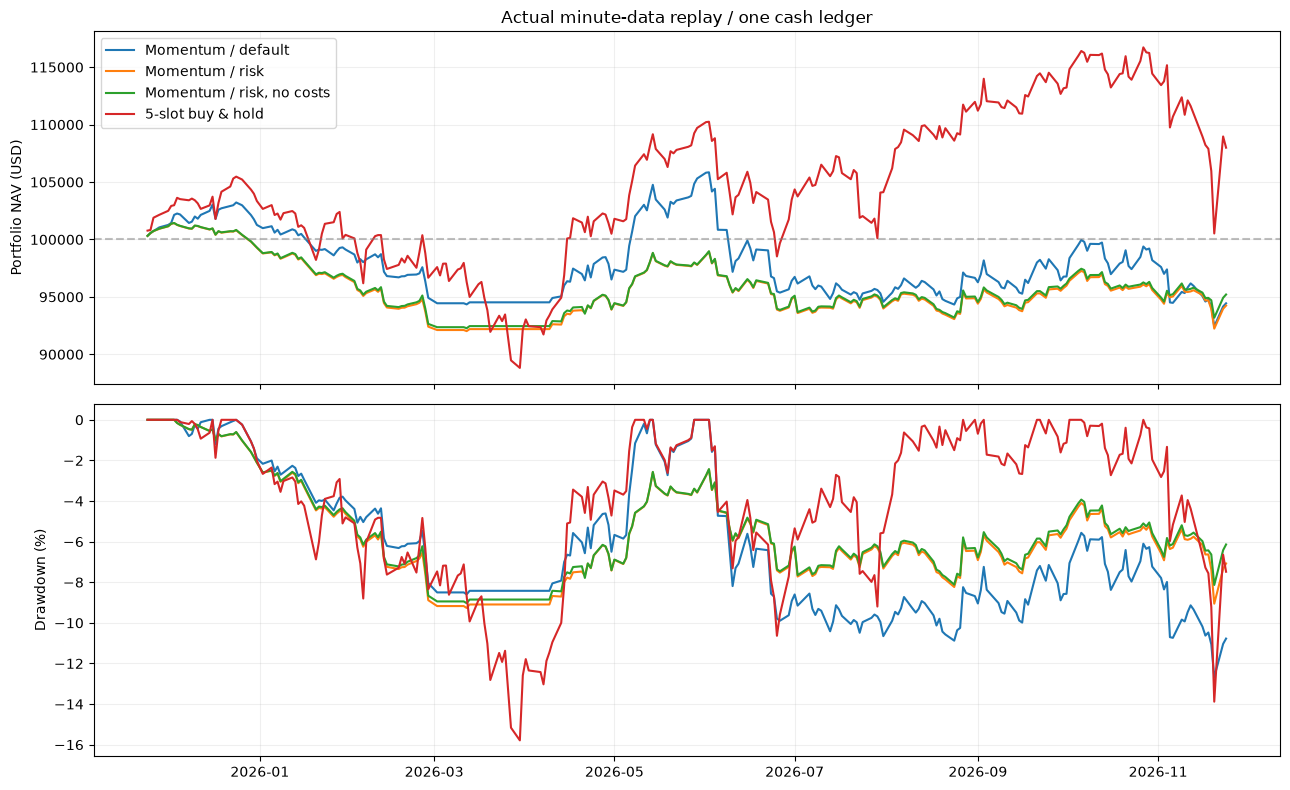

In [3]:
curves = {name: pd.DataFrame(r["curve"]).set_index("session") for name,r in results.items()}
fig, axes = plt.subplots(2,1,figsize=(13,8),sharex=True)
for name,f in curves.items():
    x = pd.to_datetime(f.index)
    axes[0].plot(x,f.equity,label=labels[name])
    values = np.r_[metadata["budget"],f.equity.to_numpy()]
    dd = values / np.maximum.accumulate(values) - 1
    axes[1].plot(x,dd[1:]*100,label=labels[name])
axes[0].axhline(metadata["budget"],color="gray",linestyle="--",alpha=.5)
axes[0].set_ylabel("Portfolio NAV (USD)")
axes[0].set_title("Actual minute-data replay / one cash ledger")
axes[0].legend(loc="best")
axes[1].set_ylabel("Drawdown (%)")
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

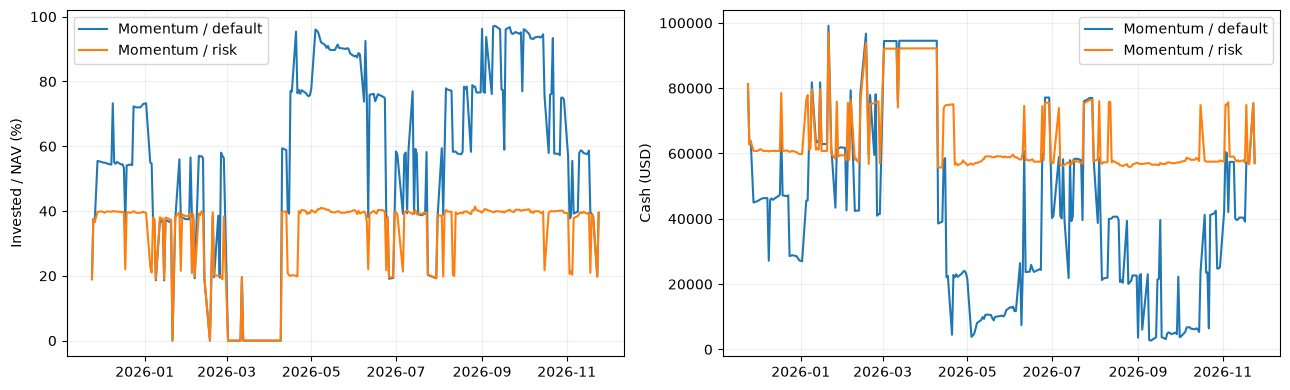

,day/symbol alerts
rule,
sector_weight,493
position_weight,141


,min_cash,min_inventory,signal_before_fill,limit_respected,sessions,cash_inventory_nav_reconciled,split_events
Momentum / default,2679.14208886877421474506630,0,True,True,252,True,0
Momentum / risk,55716.92608907292869481239655,0,True,True,252,True,0
"Momentum / risk, no costs",55990.77500000,0,True,True,252,True,0
5-slot buy & hold,28.97825809794202557806725,0,True,True,252,True,0


In [4]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
for name in ["momentum_unrestricted_net","momentum_risk_net"]:
    f = curves[name]
    axes[0].plot(pd.to_datetime(f.index),f.gross_weight*100,label=labels[name])
    axes[1].plot(pd.to_datetime(f.index),pd.to_numeric(f.cash),label=labels[name])
axes[0].set_ylabel("Invested / NAV (%)")
axes[1].set_ylabel("Cash (USD)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()
events = pd.DataFrame(results["momentum_risk_net"]["risk_events"])
if len(events):
    display(events.groupby("rule").size().rename("day/symbol alerts").sort_values(ascending=False).to_frame())
display(pd.DataFrame({labels[name]:r["audit"] for name,r in results.items()}).T)

In [5]:
policy = results["momentum_risk_net"]["config"]
display(pd.DataFrame([policy["order_policy"]]))
display(pd.DataFrame([{k:v for k,v in policy["risk_limits"].items() if k != "sectors"}]))
print("Order policy:", policy["order_policy_version"], "| risk policy:", policy["risk_policy_version"])
for limitation in metadata["limitations"]:
    print("•",limitation)
status_path = REPO_DIR / "artifacts/paper_risk_public/status.json"
if status_path.exists():
    live_risk = json.loads(status_path.read_text())
    print("Latest paper risk check:",live_risk["checked_at"],live_risk["status"])
    display(pd.DataFrame(live_risk.get("alerts",[])))

,target_fraction,collar,commission_bps,slippage_bps,spread_bps,impact_bps,minute_participation
0,0.95,0.01,1.0,2.0,2.0,5.0,0.01


,daily_loss,drawdown,gross_weight,position_weight,sector_weight,correlated_weight,correlation_threshold,portfolio_volatility,adv_participation
0,0.02,0.1,0.95,0.2,0.4,0.4,0.8,0.25,0.01


Order policy: 814c736a623c72b6 | risk policy: 5d7bc1a512637b45
• OHLC limit touches and 1% observed minute-volume cap; not NBBO queue or random Alpaca matching
• no after-hours, dividends, interest, taxes, delisted-universe correction or historical revision archive
• unknown sectors grouped as UNCLASSIFIED with 40% cap; no ETF look-through
• no forced liquidation: risk blocks buys/cancels own pending buys; price losses may exceed thresholds
• drawdown halt latches until explicit operator reset; no reset during historical evaluation
• fixed universe and unchanged default limits, no performance optimization
• marks carried only between observed minutes; risk checked after completed bars every 5 minutes
Latest paper risk check: 2026-11-25T01:29:49.856597006-05:00 ok


,rule,severity,symbol,first_seen,last_seen,observations
0,sector_unclassified,info,PORTFOLIO,2026-11-25T00:04:08.570807232-05:00,2026-11-25T00:14:37.655554333-05:00,3
1,sector_unclassified,info,PORTFOLIO,2026-11-24T23:14:45.927958689-05:00,2026-11-24T23:58:54.587568517-05:00,13


리스크 한도는 최적화하지 않은 초기 운영값입니다. 일일 손실 2% 또는 활성화 후 낙폭 10%는 신규 매수를 멈추고 자체 대기 매수를 취소하는 기준이며, 최대 손실을 보장하지 않습니다. 매도 신호는 허용하지만 강제 청산은 추가하지 않았습니다. 일일 정지는 다음 뉴욕 날짜에 해제되고, 낙폭 정지는 명시적인 사유를 남긴 수동 초기화까지 유지됩니다.

섹터 원본 정보가 없어 모두 `UNCLASSIFIED` 그룹으로 묶었습니다. ETF 내부 종목은 분석하지 않습니다. 분봉 OHLC와 관측 거래량 1%로 체결을 모형화했으며 Alpaca의 NBBO·큐·무작위 부분 체결은 재현하지 않습니다. paper 기준 배당은 제외합니다. 비용 제외 실험도 별도로 체결·수량을 다시 계산하므로 순수익에 비용만 더한 값과 다를 수 있습니다.

공식 문서: [Alpaca Paper Trading](https://docs.alpaca.markets/us/docs/paper-trading), [Orders](https://docs.alpaca.markets/us/docs/orders-at-alpaca).